# T47D CDK4 variant RNA-seq (20260927): DESeq2, DEGs, GSEA and plots (DMSO only)

Everything loads from **this folder**, and figures are saved as PNG + SVG in `T47D_CDK4_20260927_results/figures/`.

**Samples.** 12 T47D samples = 4 genotypes × vehicle (DMSO) × 3 replicates. 

| Genotype | Role |
|---|---|
| `CBE_NT` | **matched control**: all variant-vs-control contrasts use it |
| `CDK4_D196N`, `CDK4_E56K`, `CDK4_W198` (W198\*, nonsense) | CDK4 variants |

Inputs: `salmon.merged.gene_counts_scaled.tsv` (DESeq2, **needs to be copied into this folder** from the nf-core `star_salmon/` output)
and `salmon.merged.gene_tpm.tsv` (log2(TPM+1) for PCA, heatmaps and the CDK4 plot).

In [1]:
# ── Imports & style ──────────────────────────────────────────────────────────
%matplotlib inline

from pathlib import Path
import json, re, shutil
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats as sps
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans']
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['svg.fonttype'] = 'none'   # keep SVG text editable in Illustrator
plt.rcParams['figure.dpi'] = 110

In [2]:
# ── Paths (all local to this notebook's folder) ──────────────────────────────
BASE = Path.cwd()
COUNTS_FILE  = BASE / 'salmon.merged.gene_counts_scaled.tsv'   # DESeq2 input
EXPR_FILE    = BASE / 'salmon.merged.gene_tpm.tsv'             # log2(TPM+1) for plots

RESULTS_ROOT   = BASE / 'T47D_CDK4_20260927_results'
RESULTS_DIR    = RESULTS_ROOT / 'deseq2_results'
DEG_DIR        = RESULTS_ROOT / 'DEG_tables_DMSO'
FIG_DIR        = RESULTS_ROOT / 'figures'
HALLMARK_CACHE = RESULTS_ROOT / 'hallmark_gene_sets_cache.json'
for d in (RESULTS_DIR, DEG_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f"Working folder: {BASE}\n")
for label, p in [('scaled counts', COUNTS_FILE), ('TPM matrix', EXPR_FILE),
                 ('Hallmark cache', HALLMARK_CACHE)]:
    print(f"  {'FOUND ' if p.exists() else 'MISSING'}  {label:15s} {p.name}")

Working folder: /home/claude/run

  FOUND   scaled counts   salmon.merged.gene_counts_scaled.tsv
  FOUND   TPM matrix      salmon.merged.gene_tpm.tsv
  FOUND   Hallmark cache  hallmark_gene_sets_cache.json


In [ ]:
# ── Genotypes, matched control, comparison definitions ───────────────────────
CONTROL_FOR = {                 # variant -> matched control
    'CDK4_D196N': 'CBE_NT',
    'CDK4_E56K':  'CBE_NT',
    'CDK4_W198':  'CBE_NT',     # W198* (nonsense); written 'W198' in the sample names
}
VARIANTS  = list(CONTROL_FOR)
CONTROLS  = ['CBE_NT']
GENOTYPES = CONTROLS + VARIANTS
REF       = 'CBE_NT'

variant_vs_control_veh = [(f'{v}_veh', f'{c}_veh', f'{v}_vs_{c}_veh', f'{v} vs {c} (DMSO)') for v, c in CONTROL_FOR.items()]
comparisons = variant_vs_control_veh

# Display names: 'CDK4_W198' -> 'CDK4 W198*', 'CBE_NT' -> 'CBE NT'
LABELS = {'CBE_NT': 'CBE NT', 'CDK4_D196N': 'CDK4 D196N', 'CDK4_E56K': 'CDK4 E56K', 'CDK4_W198': 'CDK4 W198*'}
_LABEL_RE = re.compile(r'\b(' + '|'.join(sorted(LABELS, key=len, reverse=True)) + r')\b')
def pretty_label(text):
    # Swap every genotype key in a string for its display name.
    return _LABEL_RE.sub(lambda m: LABELS[m.group(1)], str(text))
lab = pretty_label

# Colours: control grey, one colour per CDK4 variant.
CELL_LINE_COLORS = {
    'CBE_NT': '#8C8C86',
    'CDK4_D196N': '#5B84B1', 'CDK4_E56K': '#9A82B0', 'CDK4_W198': '#D9702E',
}
treatment_markers = {'veh': 'o', 'palbo': '^'}           # circle = DMSO, triangle = Palbo
treatment_labels  = {'veh': 'DMSO', 'palbo': 'Palbo'}
[c[2] for c in comparisons]

['CDK4_D196N_vs_CBE_NT_veh',
 'CDK4_E56K_vs_CBE_NT_veh',
 'CDK4_W198_vs_CBE_NT_veh']

## DESeq2 (PyDESeq2)

One shared model `~condition` over the 4 DMSO genotype groups (12 samples), with Cook's-outlier refitting. Genes
are kept if they have ≥ 10 counts in ≥ 3 samples. `log2FoldChange` is the unshrunken MLE, as in the earlier tables.
Each contrast is written to `deseq2_results/<name>.csv` (gene_id, baseMean, log2FoldChange, lfcSE, stat, pvalue, padj, gene_name).
If all CSVs are already there they are loaded instead of refitting. Set `RECOMPUTE = True` to force a refit.

In [4]:
# ── Run (or load cached) DESeq2 ──────────────────────────────────────────────
RECOMPUTE = False
MIN_COUNT, MIN_SAMPLES = 10, 3
COLS = ['baseMean', 'log2FoldChange', 'lfcSE', 'stat', 'pvalue', 'padj']

csvs = {name: RESULTS_DIR / f'{name}.csv' for _, _, name, _ in comparisons}
if RECOMPUTE or not all(p.exists() for p in csvs.values()):
    import time
    from pydeseq2.dds import DeseqDataSet
    from pydeseq2.ds import DeseqStats

    if not COUNTS_FILE.exists():
        raise FileNotFoundError(f'{COUNTS_FILE.name} is not in this folder. Copy it from the nf-core '
                                f'star_salmon/ output (DESeq2 needs counts, not TPM).')
    raw = pd.read_csv(COUNTS_FILE, sep='\t', index_col=0)
    gene_name_map = raw['gene_name']
    counts = raw.drop(columns=['gene_name'])
    keep = (counts >= MIN_COUNT).sum(axis=1) >= MIN_SAMPLES
    counts = counts.loc[keep]

    parsed = counts.columns.str.extract(r'^T47D_(?P<genotype>.+)_(?P<treatment>palbo|veh)_\d+$')
    dmeta = pd.DataFrame({'genotype': parsed['genotype'].values,
                          'treatment': parsed['treatment'].values}, index=counts.columns)
    dmeta['condition'] = dmeta['genotype'] + '_' + dmeta['treatment']
    assert set(dmeta['genotype']) == set(GENOTYPES), set(dmeta['genotype'])
    print(f"{keep.sum()} / {len(keep)} genes pass the filter; "
          f"{dmeta.condition.nunique()} conditions x {dmeta.groupby('condition').size().unique()} reps")

    X = counts.T.round(0).astype(int)                     # samples x genes
    t0 = time.time()
    try:
        dds = DeseqDataSet(counts=X, metadata=dmeta, design='~condition', refit_cooks=True, quiet=True)
    except TypeError:                                     # older PyDESeq2
        dds = DeseqDataSet(counts=X, metadata=dmeta, design_factors='condition', refit_cooks=True)
    dds.deseq2()
    print(f"DESeq2 model fitted in {time.time() - t0:.0f}s")

    pd.DataFrame(dds.layers['normed_counts'].T, index=X.columns, columns=X.index) \
      .assign(gene_name=gene_name_map.reindex(X.columns).values) \
      .to_csv(RESULTS_DIR / 'deseq2_normalized_counts.csv')

    for test, ref, name, _ in comparisons:
        st = DeseqStats(dds, contrast=['condition', test, ref], quiet=True)
        st.summary()
        df = st.results_df[COLS].copy()
        df['gene_name'] = gene_name_map.reindex(df.index).values
        df.index.name = 'gene_id'
        df.to_csv(csvs[name])
        print(f"  wrote {name}.csv")
else:
    print("Loading cached DESeq2 results (set RECOMPUTE = True to refit).")

results = {name: (pd.read_csv(csvs[name]), title) for _, _, name, title in comparisons}
print(f"{len(results)} contrasts loaded; {len(next(iter(results.values()))[0])} genes tested.")

Loading cached DESeq2 results (set RECOMPUTE = True to refit).
3 contrasts loaded; 16896 genes tested.


## Normalized expression matrix

`log_expr` = log2(TPM + 1), genes × samples. `metadata` and `sample_order` are parsed from the sample names, and `ARMS` lists the
treatment arms present (only `veh` in this run). `sym2id` maps a gene symbol to its Ensembl ID (if a symbol has more than one ID,
the more highly expressed one is used).

In [5]:
# ── Load TPM ─────────────────────────────────────────────────────────────────
expr = pd.read_csv(EXPR_FILE, sep='\t', index_col=0)
expr_gene_names = expr['gene_name'].copy()
expr = expr.drop(columns=['gene_name'])

parsed = expr.columns.str.extract(r'^T47D_(?P<genotype>.+)_(?P<treatment>palbo|veh)_\d+$')
metadata = pd.DataFrame({'genotype': parsed['genotype'].values,
                         'treatment': parsed['treatment'].values}, index=expr.columns)
metadata['condition'] = metadata['genotype'] + '_' + metadata['treatment']
log_expr = np.log2(expr + 1)

sample_order = (metadata.reset_index().rename(columns={'index': 'sample'})
    .assign(gr=lambda d: d['genotype'].map({g: i for i, g in enumerate(GENOTYPES)}),
            tr=lambda d: d['treatment'].map({'veh': 0, 'palbo': 1}))
    .sort_values(['gr', 'tr', 'sample'])['sample'].tolist())

_mean = log_expr.mean(axis=1)
sym2id = (pd.DataFrame({'sym': expr_gene_names, 'm': _mean})
          .sort_values('m', ascending=False).drop_duplicates('sym')['sym'])
sym2id = pd.Series(sym2id.index, index=sym2id.values)
print(f"Expression: {log_expr.shape[0]} genes x {log_expr.shape[1]} samples")

ARMS = [t for t in ('veh', 'palbo') if t in set(metadata['treatment'])]
assert set(metadata['genotype']) == set(GENOTYPES), set(metadata['genotype'])
print('Arms present:', [treatment_labels[a] for a in ARMS])
print(metadata.groupby(['genotype', 'treatment']).size().rename('n').to_frame().T)

Expression: 78458 genes x 12 samples
Arms present: ['DMSO']
genotype  CBE_NT CDK4_D196N CDK4_E56K CDK4_W198
treatment    veh        veh       veh       veh
n              3          3         3         3


## Hallmark gene sets

The **full MSigDB Hallmark 2020 collection (50 sets)** is downloaded from Enrichr once and cached in
`T47D_CDK4_20260927_results/hallmark_gene_sets_cache.json`. When offline, the notebook falls back to whatever is cached
(you can also copy the cache from the 20260918 results folder). It is loaded here because the volcano plots, GSEA and E2F score all use it.

In [6]:
# ── GSEA setup ───────────────────────────────────────────────────────────────
import gseapy as gs
HALLMARK_LIBRARY = 'MSigDB_Hallmark_2020'

def load_hallmark(cache_file=HALLMARK_CACHE, library=HALLMARK_LIBRARY):
    cached = json.loads(cache_file.read_text()) if cache_file.exists() else {}
    if len(cached) >= 50:
        return cached
    try:
        lib = gs.get_library(name=library, organism='Human')
        cache_file.write_text(json.dumps(lib))
        print(f"Downloaded {len(lib)} Hallmark sets -> {cache_file.name}")
        return lib
    except Exception as e:
        print(f"Could not download Hallmark sets ({type(e).__name__}); using the {len(cached)} cached sets.")
        return cached

HALLMARK = load_hallmark()

def run_gsea(res_dict, gene_sets, label=''):
    out = {}
    for key, res in res_dict.items():
        rc = res.dropna(subset=['stat', 'gene_name']).drop_duplicates(subset='gene_name')
        rnk = rc[['gene_name', 'stat']].set_index('gene_name').sort_values('stat', ascending=False)
        pre = gs.prerank(rnk=rnk, gene_sets=gene_sets, permutation_num=1000, seed=42,
                         min_size=5, max_size=500, verbose=False, outdir=None)
        d = pre.res2d.set_index('Term')
        out[key] = d[['NES', 'NOM p-val', 'FDR q-val', 'Lead_genes']].astype({'NES': float, 'NOM p-val': float, 'FDR q-val': float})
    print(f"  GSEA done: {label} ({len(out)} contrasts)")
    return out

def gsea_long(gsea_res):
    return pd.concat({k: v for k, v in gsea_res.items()}, names=['contrast', 'Term']).reset_index()

def plot_gsea_dotplot(gsea_res, terms, outpath, title=None, fdr_floor=1e-3, vmax=None):
    comps = list(gsea_res)
    nes = pd.DataFrame({c: gsea_res[c]['NES'] for c in comps}).reindex(terms)
    fdr = pd.DataFrame({c: gsea_res[c]['FDR q-val'] for c in comps}).reindex(terms)
    neglog = -np.log10(fdr.clip(lower=fdr_floor))
    SMIN, SMAX, CAP = 20, 260, -np.log10(fdr_floor)
    s_of = lambda nl: SMIN + (SMAX - SMIN) * np.clip(nl / CAP, 0, 1)
    vmax = float(np.nanmax(np.abs(nes.values))) if vmax is None else vmax
    norm = mcolors.TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)
    fig, ax = plt.subplots(figsize=(len(comps) * 0.9 + 4.2, 0.9 + len(terms) * 0.34))
    for i, t in enumerate(terms):
        for j, c in enumerate(comps):
            if pd.notna(nes.values[i, j]):
                ax.scatter(j, i, s=s_of(neglog.values[i, j]), c=[nes.values[i, j]], cmap='RdBu_r', norm=norm,
                           edgecolors='black', linewidths=0.4, zorder=3)
    ax.set_xticks(range(len(comps))); ax.set_xticklabels([lab(c) for c in comps], rotation=45, ha='right',
                                                         rotation_mode='anchor', fontsize=8)
    ax.set_yticks(range(len(terms))); ax.set_yticklabels(terms, fontsize=8)
    ax.set_xlim(-0.5, len(comps) - 0.5); ax.set_ylim(-0.5, len(terms) - 0.5); ax.invert_yaxis()
    ax.set_axisbelow(True); ax.grid(True, color='#EEEEEE', lw=0.6)
    ax.spines[['top', 'right']].set_visible(False)
    sm = plt.cm.ScalarMappable(norm=norm, cmap='RdBu_r'); sm.set_array([])
    cb = plt.colorbar(sm, ax=ax, shrink=0.5 if len(terms) > 8 else 0.9, pad=0.02, aspect=12)
    cb.set_label('NES', fontsize=8); cb.ax.tick_params(labelsize=7)
    handles = [ax.scatter([], [], s=s_of(-np.log10(max(f, fdr_floor))), color='#BBBBBB', edgecolors='black',
                          linewidths=0.4, label=f'{f:g}') for f in [0.25, 0.05, 0.01, 0.001]]
    ax.legend(handles=handles, title='FDR q-val', fontsize=7, title_fontsize=7, frameon=False,
              loc='upper left', bbox_to_anchor=(1.28, 1.0), labelspacing=1.0)
    if title:
        ax.set_title(title, fontsize=10)
    plt.tight_layout()
    plt.savefig(f'{outpath}.svg', dpi=300, bbox_inches='tight')
    plt.savefig(f'{outpath}.png', dpi=300, bbox_inches='tight')
    plt.show()

## CDK4 transcript levels: NMD check for W198\*

CDK4 TPM per replicate for every genotype (DMSO). Bars show the group mean and markers the replicates. The dashed line is the CBE NT mean.
Above each variant: fold change vs CBE NT (TPM ratio) and DESeq2 FDR for that variant-vs-CBE NT contrast
(`*` < 0.05, `**` < 0.01, `***` < 0.001). A PTC-containing transcript that goes through NMD should show clearly lower CDK4 mRNA than the
control and the missense variants. Numbers are saved to `deseq2_results/CDK4_transcript_levels.csv`.

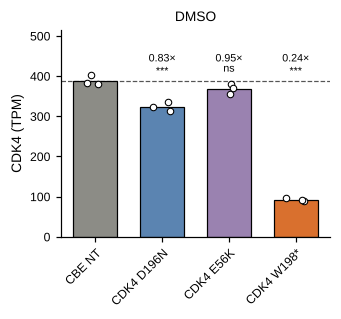

,genotype,treatment,mean_TPM,fold_vs_ctrl_TPM,deseq2_log2FC,deseq2_padj
0,CBE_NT,DMSO,388.5800,1.0000,NaN,NaN
1,CDK4_D196N,DMSO,323.6038,0.8328,-0.2318,0.0000
2,CDK4_E56K,DMSO,368.8270,0.9492,-0.0360,0.5858
3,CDK4_W198,DMSO,92.4888,0.2380,-2.0259,0.0000


In [7]:
# ── CDK4 transcript levels ──────────────────────────────────────────────────
def plot_gene_levels(gene, outpath, genotypes=GENOTYPES, ctrl='CBE_NT', arms=None, figsize=None):
    arms = list(arms or ARMS)
    figsize = figsize or (2.8 * len(arms) + 0.4, 3.0)
    gid = sym2id[gene]
    tpm = expr.loc[gid]
    rows = []
    for tx in arms:
        ctrl_mean = tpm[metadata.index[(metadata.genotype == ctrl) & (metadata.treatment == tx)]].mean()
        for g in genotypes:
            s = metadata.index[(metadata.genotype == g) & (metadata.treatment == tx)]
            padj = lfc = np.nan
            if g in CONTROL_FOR:
                d = results[f'{g}_vs_{CONTROL_FOR[g]}_{tx}'][0].set_index('gene_id')
                if gid in d.index:
                    padj, lfc = d.loc[gid, 'padj'], d.loc[gid, 'log2FoldChange']
            rows.append(dict(gene=gene, genotype=g, treatment=treatment_labels[tx], mean_TPM=tpm[s].mean(),
                             sd_TPM=tpm[s].std(), reps=tpm[s].round(2).tolist(),
                             fold_vs_ctrl_TPM=tpm[s].mean() / ctrl_mean,
                             deseq2_log2FC=lfc, deseq2_padj=padj))
    tbl = pd.DataFrame(rows)
    stars = lambda p: '' if pd.isna(p) else '***' if p < 1e-3 else '**' if p < 1e-2 else '*' if p < 0.05 else 'ns'

    fig, axes = plt.subplots(1, len(arms), figsize=figsize, sharey=True, squeeze=False)
    axes = axes[0]
    rng = np.random.default_rng(0)
    ymax = tbl['reps'].explode().astype(float).max()
    for ax, tx in zip(axes, arms):
        sub = tbl[tbl.treatment == treatment_labels[tx]].set_index('genotype').loc[genotypes]
        x = np.arange(len(genotypes))
        ax.bar(x, sub['mean_TPM'], width=0.66, color=[CELL_LINE_COLORS[g] for g in genotypes],
               edgecolor='black', linewidth=0.8, zorder=2)
        for xi, g in enumerate(genotypes):
            r = np.array(sub.loc[g, 'reps'], dtype=float)
            ax.scatter(xi + rng.uniform(-0.14, 0.14, len(r)), r, s=18, marker=treatment_markers[tx],
                       facecolor='white', edgecolor='black', linewidth=0.7, zorder=4)
            if g in CONTROL_FOR:
                ax.text(xi, max(r.max(), sub.loc[ctrl, 'mean_TPM']) + ymax * 0.04, f"{sub.loc[g, 'fold_vs_ctrl_TPM']:.2f}×\n{stars(sub.loc[g, 'deseq2_padj'])}",
                        ha='center', va='bottom', fontsize=7, linespacing=1.1)
        ax.axhline(sub.loc[ctrl, 'mean_TPM'], color='#555555', lw=0.8, ls='--', zorder=1)
        ax.set_xticks(x); ax.set_xticklabels([lab(g) for g in genotypes], rotation=45, ha='right',
                                             rotation_mode='anchor', fontsize=8)
        ax.set_title(treatment_labels[tx], fontsize=9)
        ax.spines[['top', 'right']].set_visible(False)
        ax.tick_params(labelsize=8)
    axes[0].set_ylabel(f'{gene} (TPM)', fontsize=9)
    axes[0].set_ylim(0, ymax * 1.28)
    plt.tight_layout()
    plt.savefig(f'{outpath}.svg', dpi=300, bbox_inches='tight')
    plt.savefig(f'{outpath}.png', dpi=300, bbox_inches='tight')
    plt.show()
    return tbl

cdk4_tbl = plot_gene_levels('CDK4', FIG_DIR / 'CDK4_transcript_levels')
cdk4_tbl.drop(columns='reps').to_csv(RESULTS_DIR / 'CDK4_transcript_levels.csv', index=False)
cdk4_tbl[['genotype', 'treatment', 'mean_TPM', 'fold_vs_ctrl_TPM', 'deseq2_log2FC', 'deseq2_padj']].round(4)

### Volcano plots

`plot_volcano_grid` works in two modes. `label_mode='top'` labels the `N_LABELS` most significant DEGs, which is what the DMSO
DEG panels use. `label_mode='cell_cycle'` is the April style: E2F Targets genes in orange, G2-M in magenta, both in black,
and the top cell-cycle genes labelled. **CDK4 is always marked** (black ring) so you can see where it falls. The x-axis is fixed at ±`X_LIM`, and the y-axis is
shared within each grid.

In [8]:
# ── DEG thresholds + calls (DMSO), used by the volcano and overlap plots ─────
LFC_THRESH, PADJ_THRESH = 1.0, 0.05
UP_COLOR, DOWN_COLOR, NS_COLOR, THRESH_COLOR = '#d6604d', '#4393c3', '#d0d0d0', '#999999'

def call_degs(res, lfc=LFC_THRESH, padj=PADJ_THRESH):
    r = res.dropna(subset=['padj', 'log2FoldChange']).copy()
    r['direction'] = np.where(r['log2FoldChange'] > 0, 'up', 'down')
    return r[(r['padj'] < padj) & (r['log2FoldChange'].abs() > lfc)].sort_values('padj')

deg_veh = {v: call_degs(results[f'{v}_vs_{CONTROL_FOR[v]}_veh'][0]) for v in VARIANTS}

# ── Volcano function ─────────────────────────────────────────────────────────
try:
    from adjustText import adjust_text
    HAS_ADJUSTTEXT = True
except ImportError:
    HAS_ADJUSTTEXT = False
    print("adjustText not installed — labels may overlap. Install: pip install adjustText")

X_LIM, N_LABELS = 6, 12
ALWAYS_MARK = ['CDK4']

_E2F, _G2M = set(HALLMARK.get('E2F Targets', [])), set(HALLMARK.get('G2-M Checkpoint', []))
CC_STYLE = {'E2F Targets': ('#e6850d', _E2F - _G2M), 'G2-M Checkpoint': ('#c51b8a', _G2M - _E2F),
            'E2F + G2-M': ('#000000', _E2F & _G2M)}
CC_ALL = _E2F | _G2M

def plot_volcano_grid(comparison_list, ncols, outpath, label_mode='top', panel=4.3):
    nrows = int(np.ceil(len(comparison_list) / ncols))
    ys = [-np.log10(results[n][0]['padj'].dropna().clip(lower=1e-300)) for _, _, n, _ in comparison_list]
    y_lim = np.ceil(max(y.max() for y in ys)) * 1.05 + 1
    fig, axes = plt.subplots(nrows, ncols, figsize=(panel * ncols, panel * nrows), squeeze=False)
    axes = axes.flatten()
    for k, (ax, (_, _, name, title)) in enumerate(zip(axes, comparison_list)):
        rc = results[name][0].dropna(subset=['padj', 'log2FoldChange']).copy()
        rc['y'] = -np.log10(rc['padj'].clip(lower=1e-300))
        rc['x'] = rc['log2FoldChange'].clip(-X_LIM * 0.98, X_LIM * 0.98)    # pin out-of-range genes to the edge
        up   = (rc['padj'] < PADJ_THRESH) & (rc['log2FoldChange'] >  LFC_THRESH)
        down = (rc['padj'] < PADJ_THRESH) & (rc['log2FoldChange'] < -LFC_THRESH)
        ns = ~(up | down)
        ax.scatter(rc.loc[ns, 'x'], rc.loc[ns, 'y'], s=4, color=NS_COLOR, alpha=0.5, lw=0, rasterized=True)
        up_pts = ax.scatter(rc.loc[up, 'x'], rc.loc[up, 'y'], s=10, color=UP_COLOR, alpha=0.85, lw=0, rasterized=True)
        dn_pts = ax.scatter(rc.loc[down, 'x'], rc.loc[down, 'y'], s=10, color=DOWN_COLOR, alpha=0.85, lw=0, rasterized=True)

        if label_mode == 'cell_cycle':
            for lbl, (col, gset) in CC_STYLE.items():
                sel = rc[rc['gene_name'].isin(gset)]
                ax.scatter(sel['x'], sel['y'], s=20, color=col, edgecolors='black', lw=0.3, zorder=5,
                           label=(lbl if k == 0 else None))
            pool = rc[rc['gene_name'].isin(CC_ALL) & (up | down)]
        else:
            pool = rc[up | down]
        to_label = pool.nsmallest(N_LABELS, 'padj')
        mark = rc[rc['gene_name'].isin(ALWAYS_MARK)]
        ax.scatter(mark['x'], mark['y'], s=40, facecolor='none', edgecolor='black', lw=1.0, zorder=6)
        to_label = pd.concat([to_label, mark]).drop_duplicates('gene_id')
        texts = [ax.text(r['x'], r['y'], r['gene_name'], fontsize=7, style='italic')
                 for _, r in to_label.iterrows()]
        if HAS_ADJUSTTEXT and texts:
            adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle='-', color='black', lw=0.4), expand=(1.2, 1.4),
                        time_lim=5, iter_lim=300)   # cap so a crowded panel can't hang

        ax.set_xlim(-X_LIM, X_LIM); ax.set_ylim(0, y_lim)
        for xv in (LFC_THRESH, -LFC_THRESH):
            ax.axvline(xv, color=THRESH_COLOR, lw=1.0, ls='--', alpha=0.8)
        ax.axhline(-np.log10(PADJ_THRESH), color=THRESH_COLOR, lw=1.0, ls='--', alpha=0.8)
        ax.spines[['top', 'right']].set_visible(False)
        ax.set_xlabel(r'log$_2$ fold change', fontsize=10); ax.set_ylabel(r'-log$_{10}$(padj)', fontsize=10)
        ax.set_title(pretty_label(title), fontsize=10)
        leg = ax.legend(handles=[up_pts, dn_pts], labels=[f'{int(up.sum())} DE UP', f'{int(down.sum())} DE DOWN'],
                        loc='upper right', fontsize=8, frameon=True, framealpha=1, edgecolor='#cccccc')
        ax.add_artist(leg)
    for ax in axes[len(comparison_list):]:
        ax.axis('off')
    if label_mode == 'cell_cycle':
        axes[0].legend(fontsize=7, frameon=False, loc='upper left', title='Cell cycle', title_fontsize=7)
    plt.tight_layout()
    plt.savefig(f'{outpath}.svg', dpi=300, bbox_inches='tight')
    plt.savefig(f'{outpath}.png', dpi=300, bbox_inches='tight')
    plt.show()

Both time_lim and iter_lim are set, faster will be used


Both time_lim and iter_lim are set, faster will be used


Both time_lim and iter_lim are set, faster will be used


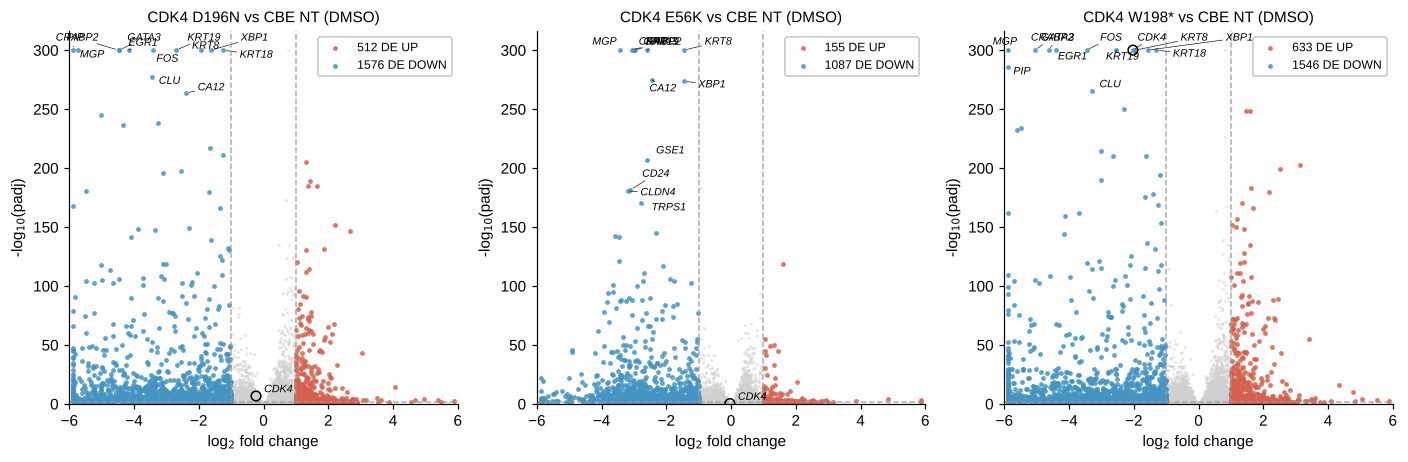

In [9]:
# DMSO: each variant vs CBE NT, top DEGs labelled
plot_volcano_grid(variant_vs_control_veh, ncols=3, outpath=FIG_DIR / 'volcano_variant_vs_control_DMSO',
                  label_mode='top')

### DEG overlap between variants (DMSO)

The UpSet-style plot counts DEGs (any direction) in each combination of variants. For shared genes, `direction_concordant`
in the saved table shows whether they move the same way in every variant. The heatmap to the right shows log2FC vs CBE NT
for the union of each variant's top `N_TOP_EACH` DEGs. Rows are hierarchically clustered, and each cell is marked `*` / `**` / `***` by FDR.

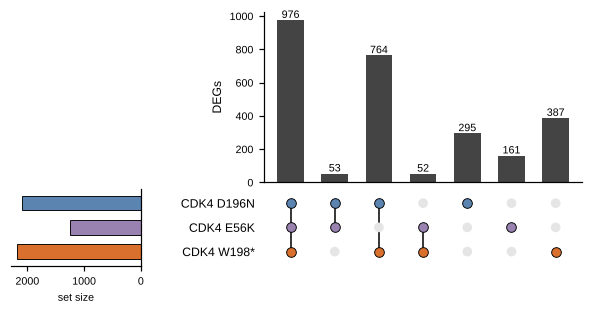

Shared by all variants: CFH, HECW1, PRSS22, ACSM3, CRLF1, YBX2, TMEM132A, KDM7A, ARSD, TRAPPC6A, CYB561, PLEKHG6, MLXIPL, SYT7, ANGEL1, CHDH, IL20RA, NLRP2, FAS, KCNG1, SH3YL1, USP2, FLT4, HOXC8, CDH1, RIPOR3, BARX2, CTPS2, EPN3, ARHGEF5, PTGER3, PRSS8, ENTPD2, ATP9A, IL17RB, TBXAS1, CDH3, ADCK1, DLX3, ATP2C2, FAR2, NTN1, ERBB3, GSTO2, TLE2, FGFR2, NEO1, ROGDI, PDK3, FGFR3, ADGRF5, GAL, HES2, VASH1, TRIP13, CDH19, ADGRL1, RPS6KA6, SIDT1, LLGL2


In [10]:
# ── DEG overlap (UpSet-style) + saved membership table ───────────────────────
from itertools import combinations
sets = {v: set(deg_veh[v]['gene_id']) for v in VARIANTS}
combos = []
for r in range(len(VARIANTS), 0, -1):
    for combo in combinations(VARIANTS, r):
        inside = set.intersection(*(sets[v] for v in combo))
        outside = set().union(*(sets[v] for v in VARIANTS if v not in combo))
        combos.append((combo, inside - outside))
combos = [c for c in combos if len(c[1])] or combos

fig = plt.figure(figsize=(0.5 * len(combos) + 3.2, 3.0))
gs_ = fig.add_gridspec(2, 2, height_ratios=[2.2, 1], width_ratios=[1, 0.35 * len(combos)], hspace=0.05, wspace=0.55)
axb, axm, axs = fig.add_subplot(gs_[0, 1]), fig.add_subplot(gs_[1, 1]), fig.add_subplot(gs_[1, 0])
xs = np.arange(len(combos))
axb.bar(xs, [len(g) for _, g in combos], color='#444444', width=0.6)
for x, (_, g) in zip(xs, combos):
    axb.text(x, len(g), str(len(g)), ha='center', va='bottom', fontsize=7)
axb.set_xlim(-0.6, len(combos) - 0.4); axb.set_xticks([]); axb.spines[['top', 'right']].set_visible(False)
axb.set_ylabel('DEGs', fontsize=8); axb.tick_params(labelsize=7)
for yi, v in enumerate(VARIANTS[::-1]):
    for x, (combo, _) in zip(xs, combos):
        on = v in combo
        axm.scatter(x, yi, s=40, color=CELL_LINE_COLORS[v] if on else '#e5e5e5', edgecolor='black' if on else 'none', lw=0.6, zorder=3)
for x, (combo, _) in zip(xs, combos):
    idx = [VARIANTS[::-1].index(v) for v in combo]
    if len(idx) > 1:
        axm.plot([x, x], [min(idx), max(idx)], color='black', lw=1, zorder=2)
axm.set_xlim(-0.6, len(combos) - 0.4); axm.set_ylim(-0.6, len(VARIANTS) - 0.4)
axm.set_xticks([]); axm.set_yticks(range(len(VARIANTS)))
axm.set_yticklabels([lab(v) for v in VARIANTS[::-1]], fontsize=8)
axm.tick_params(axis='y', length=0, pad=6); axm.spines[:].set_visible(False)
axs.barh(range(len(VARIANTS)), [len(sets[v]) for v in VARIANTS[::-1]],
         color=[CELL_LINE_COLORS[v] for v in VARIANTS[::-1]], edgecolor='black', lw=0.6, height=0.6)
axs.invert_xaxis(); axs.set_ylim(-0.6, len(VARIANTS) - 0.4); axs.set_yticks([])
axs.tick_params(axis='x', labelsize=7)
axs.spines[['top', 'left']].set_visible(False); axs.set_xlabel('set size', fontsize=7)
plt.savefig(FIG_DIR / 'DEG_overlap_upset_DMSO.svg', dpi=300, bbox_inches='tight')
plt.savefig(FIG_DIR / 'DEG_overlap_upset_DMSO.png', dpi=300, bbox_inches='tight')
plt.show()

# membership / direction table for every DEG in any variant
lfc_veh = pd.DataFrame({v: results[f'{v}_vs_{CONTROL_FOR[v]}_veh'][0].set_index('gene_id')['log2FoldChange'] for v in VARIANTS})
padj_veh = pd.DataFrame({v: results[f'{v}_vs_{CONTROL_FOR[v]}_veh'][0].set_index('gene_id')['padj'] for v in VARIANTS})
all_deg = sorted(set().union(*sets.values()))
member = pd.DataFrame({f'DEG_{v}': [g in sets[v] for g in all_deg] for v in VARIANTS}, index=all_deg)
member.insert(0, 'gene_name', expr_gene_names.reindex(all_deg).values)
member['n_variants'] = member.filter(like='DEG_').sum(axis=1)
sgn = np.sign(lfc_veh.loc[all_deg]).where(member.filter(like='DEG_').values)
member['direction_concordant'] = sgn.apply(lambda r: r.dropna().nunique() == 1, axis=1)
member = member.join(lfc_veh.add_prefix('log2FC_')).join(padj_veh.add_prefix('padj_'))
member.sort_values(['n_variants', 'gene_name'], ascending=[False, True]).to_csv(DEG_DIR / 'DEG_overlap_DMSO.csv')
print('Shared by all variants:', ', '.join(member.loc[member.n_variants == len(VARIANTS), 'gene_name'].astype(str).tolist()[:60]) or 'none')

## PCA

Top 500 most-variable genes in `log_expr`, mean-centered, then SVD. Color = genotype (● DMSO). With only 12 samples, also look at
PC3 in `PCA_scores.csv` if PC1/PC2 are dominated by a single line.

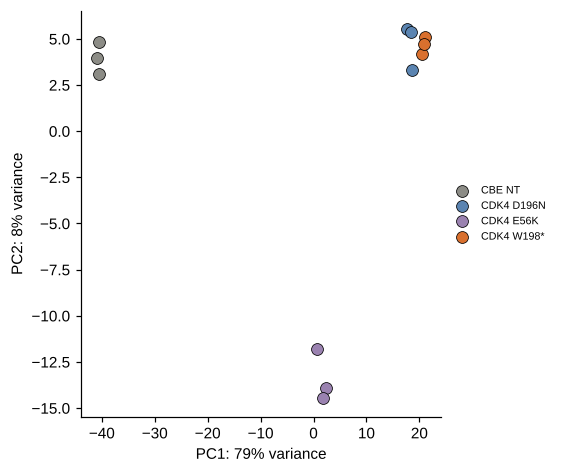

In [11]:
# ── PCA ──────────────────────────────────────────────────────────────────────
N_TOP = 500
X = log_expr.T
top_genes = X.var(axis=0).sort_values(ascending=False).head(N_TOP).index
Xc = X[top_genes] - X[top_genes].mean(axis=0)
U, S, Vt = np.linalg.svd(Xc.values, full_matrices=False)
scores = U * S
var_pct = S ** 2 / np.sum(S ** 2) * 100
pca_df = pd.DataFrame({'PC1': scores[:, 0], 'PC2': scores[:, 1], 'PC3': scores[:, 2]}, index=X.index).join(metadata)
pca_df.to_csv(RESULTS_DIR / 'PCA_scores.csv')

fig, ax = plt.subplots(figsize=(5.2, 4.4))
for g in GENOTYPES:
    for tx in ARMS:
        grp = pca_df[(pca_df.genotype == g) & (pca_df.treatment == tx)]
        ax.scatter(grp['PC1'], grp['PC2'], color=CELL_LINE_COLORS[g], marker=treatment_markers[tx], s=60,
                   edgecolors='black', linewidths=0.5, zorder=3, label=lab(g) if len(ARMS) == 1 else f'{lab(g)} ({treatment_labels[tx]})')
ax.spines[['top', 'right']].set_visible(False)
ax.set_xlabel(f'PC1: {var_pct[0]:.0f}% variance', fontsize=10)
ax.set_ylabel(f'PC2: {var_pct[1]:.0f}% variance', fontsize=10)
ax.legend(fontsize=7, frameon=False, loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.tight_layout()
plt.savefig(FIG_DIR / 'PCA.svg', dpi=300, bbox_inches='tight')
plt.savefig(FIG_DIR / 'PCA.png', dpi=300, bbox_inches='tight')
plt.show()

## Cell-cycle marker genes (DMSO)

Each gene is z-scored across the DMSO samples.

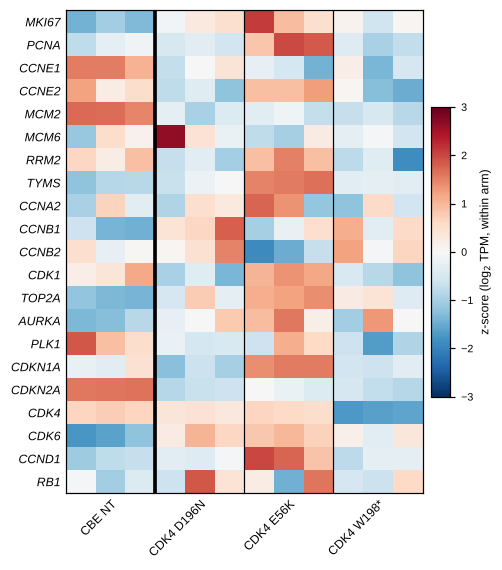

In [12]:
# ── Generic row-z heatmap, one panel per treatment arm ───────────────────────
def plot_gene_heatmap(genes, outpath, arms=('veh',), genotypes=GENOTYPES, ids=False,
                      row_h=0.2, col_w=0.22, cbar_label='z-score (log$_2$ TPM, within arm)'):
    """Row-z-scored log2(TPM+1) heatmap. `genes` = symbols (or Ensembl IDs if ids=True).
    Each arm is z-scored on its own; all panels share one colour scale."""
    gids = list(genes) if ids else [sym2id[g] for g in genes if g in sym2id.index]
    names = expr_gene_names.reindex(gids).values
    zs, ss = {}, {}
    for tx in arms:
        s = [x for x in sample_order if metadata.loc[x, 'treatment'] == tx and metadata.loc[x, 'genotype'] in genotypes]
        m = log_expr.loc[gids, s]
        zs[tx] = m.sub(m.mean(axis=1), axis=0).div(m.std(axis=1).replace(0, np.nan), axis=0)
        ss[tx] = s
    vmax = np.ceil(max(np.nanmax(np.abs(z.values)) for z in zs.values()) * 2) / 2
    ncol = len(ss[arms[0]])
    fig, axes = plt.subplots(1, len(arms), figsize=(len(arms) * col_w * ncol + 2.4, row_h * len(gids) + 1.5),
                             squeeze=False, gridspec_kw={'wspace': 0.08})
    axes = axes[0]
    for ax, tx in zip(axes, arms):
        z, s = zs[tx], ss[tx]
        im = ax.imshow(z.values, cmap='RdBu_r', vmin=-vmax, vmax=vmax, aspect='auto')
        ax.set_yticks(range(len(gids)))
        ax.set_yticklabels(names if ax is axes[0] else [], fontsize=7 if len(gids) > 30 else 8, style='italic')
        geno = metadata.loc[s, 'genotype'].values
        blocks, start = [], 0
        for i in range(1, len(geno) + 1):
            if i == len(geno) or geno[i] != geno[start]:
                blocks.append((start, i - 1, geno[start])); start = i
        ax.set_xticks([(a + b) / 2 for a, b, _ in blocks])
        ax.set_xticklabels([lab(g) for _, _, g in blocks], fontsize=8, rotation=45, ha='right', rotation_mode='anchor')
        ax.tick_params(length=0)
        for _, b, _ in blocks[:-1]:
            ax.axvline(b + 0.5, color='black', lw=0.8)
        n_ctrl = int(np.isin(geno, CONTROLS).sum())
        if 0 < n_ctrl < len(geno):
            ax.axvline(n_ctrl - 0.5, color='black', lw=2.4)
        if len(arms) > 1:
            ax.set_title(treatment_labels[tx], fontsize=10, pad=6)
    cb = fig.colorbar(im, ax=list(axes), shrink=0.6 if len(gids) > 15 else 0.9, pad=0.02, aspect=15)
    cb.set_label(cbar_label, fontsize=8); cb.ax.tick_params(labelsize=7)
    plt.savefig(f'{outpath}.svg', dpi=300, bbox_inches='tight')
    plt.savefig(f'{outpath}.png', dpi=300, bbox_inches='tight')
    plt.show()
    return zs

MARKER_GENES = ['MKI67', 'PCNA', 'CCNE1', 'CCNE2', 'MCM2', 'MCM6', 'RRM2', 'TYMS', 'CCNA2', 'CCNB1', 'CCNB2',
                'CDK1', 'TOP2A', 'AURKA', 'PLK1', 'CDKN1A', 'CDKN2A', 'CDK4', 'CDK6', 'CCND1', 'RB1']
_ = plot_gene_heatmap(MARKER_GENES, FIG_DIR / ('marker_gene_panel_' + '_'.join(treatment_labels[a] for a in ARMS)), arms=tuple(ARMS))

## E2F and G2/M scores (DMSO)

Every Hallmark E2F Targets (G1/S) or G2-M Checkpoint (G2/M) gene expressed at mean log2(TPM+1) > 1 is z-scored across all
12 samples, and the z-scores are averaged per sample (same score as in the earlier notebooks). With no palbo arm there is no DMSO → Palbo
dumbbell. Instead, each variant is compared with CBE NT in DMSO (Welch t-test, 3 vs 3, Holm-adjusted over the three variants).
Scores go to `deseq2_results/cell_cycle_phase_scores.csv`, and stats to `cell_cycle_score_stats_DMSO.csv`.

In [13]:
# ── Cell-cycle scores from TPM ──────────────────────────────────────────────
def geneset_score(symbols, min_expr=1.0):
    ids = [sym2id[g] for g in symbols if g in sym2id.index]
    m = log_expr.loc[ids]
    m = m[m.mean(axis=1) > min_expr]
    z = m.sub(m.mean(axis=1), axis=0).div(m.std(axis=1).replace(0, np.nan), axis=0)
    return z.mean(axis=0), len(m)

g1s, n1 = geneset_score(HALLMARK['E2F Targets'])
g2m, n2 = geneset_score(HALLMARK['G2-M Checkpoint'])
phase_df = metadata.assign(G1S_score=g1s, G2M_score=g2m)
phase_df.to_csv(RESULTS_DIR / 'cell_cycle_phase_scores.csv')
print(f"E2F score over {n1} genes, G2/M score over {n2} genes")
phase_df.groupby(['genotype', 'treatment'])[['G1S_score', 'G2M_score']].mean().round(2).loc[GENOTYPES]

E2F score over 198 genes, G2/M score over 192 genes


,,G1S_score,G2M_score
genotype,treatment,,
CBE_NT,veh,0.21,0.02
CDK4_D196N,veh,-0.09,0.00
CDK4_E56K,veh,0.34,0.35
CDK4_W198,veh,-0.45,-0.38


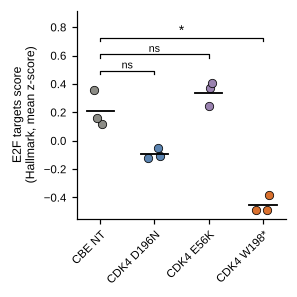

,score,variant,control,variant_mean,ctrl_mean,delta_vs_ctrl,welch_t,p,p_holm
0,G1S_score,CDK4_D196N,CBE_NT,-0.095,0.21,-0.305,-3.892,0.047,0.095
1,G1S_score,CDK4_E56K,CBE_NT,0.339,0.21,0.129,1.435,0.236,0.236
2,G1S_score,CDK4_W198,CBE_NT,-0.453,0.21,-0.663,-8.021,0.005,0.016


In [14]:
# ── E2F / G2-M score strip plot vs CBE NT (DMSO) ─────────────────────────────
def holm(p):
    p = np.asarray(p, float); out, run = np.empty(len(p)), 0.0
    for rank, i in enumerate(np.argsort(p)):
        run = max(run, min(1.0, (len(p) - rank) * p[i])); out[i] = run
    return out

stars = lambda p: '***' if p < 1e-3 else '**' if p < 1e-2 else '*' if p < 0.05 else 'ns'
SCORES = [('G1S_score', 'E2F targets score')]
veh = phase_df[phase_df.treatment == 'veh']
rows = []
for col, _ in SCORES:
    c = veh.loc[veh.genotype == REF, col].to_numpy()
    for v in VARIANTS:
        x = veh.loc[veh.genotype == v, col].to_numpy()
        t, p = sps.ttest_ind(x, c, equal_var=False)
        rows.append(dict(score=col, variant=v, control=REF, variant_mean=x.mean(), ctrl_mean=c.mean(),
                         delta_vs_ctrl=x.mean() - c.mean(), welch_t=t, p=p))
score_stats = pd.DataFrame(rows)
score_stats['p_holm'] = score_stats.groupby('score')['p'].transform(holm)
score_stats.to_csv(RESULTS_DIR / 'cell_cycle_score_stats_DMSO.csv', index=False)

fig, axes = plt.subplots(1, len(SCORES), figsize=(2.4 * len(SCORES) + 0.4, 2.8), squeeze=False)
axes = axes[0]
rng = np.random.default_rng(0)
for ax, (col, ylab) in zip(axes, SCORES):
    vals = {g: veh.loc[veh.genotype == g, col].to_numpy() for g in GENOTYPES}
    for xi, g in enumerate(GENOTYPES):
        ax.scatter(xi + rng.uniform(-0.12, 0.12, len(vals[g])), vals[g], s=30, marker='o',
                   facecolor=CELL_LINE_COLORS[g], edgecolor='black', linewidth=0.5, zorder=3)
        ax.plot([xi - 0.25, xi + 0.25], [vals[g].mean()] * 2, color='black', lw=1.2, zorder=4)
    top = max(v.max() for v in vals.values()); span = top - min(v.min() for v in vals.values())
    for k, v in enumerate(VARIANTS):
        xv = GENOTYPES.index(v); yb = top + span * (0.10 + 0.13 * k)
        ax.plot([0, 0, xv, xv], [yb - span * 0.03, yb, yb, yb - span * 0.03], color='black', lw=0.8)
        sig = stars(score_stats.query('score == @col and variant == @v')['p_holm'].iloc[0])
        ax.text(xv / 2, yb, sig, ha='center', va='bottom', fontsize=7 if sig == 'ns' else 9)
    ax.set_ylim(top=top + span * (0.18 + 0.13 * len(VARIANTS)))
    ax.set_xticks(range(len(GENOTYPES)))
    ax.set_xticklabels([lab(g) for g in GENOTYPES], rotation=45, ha='right', rotation_mode='anchor', fontsize=8)
    ax.set_ylabel(f'{ylab}\n(Hallmark, mean z-score)', fontsize=8); ax.tick_params(labelsize=7.5)
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
for ext in ('png', 'svg'):
    fig.savefig(FIG_DIR / f'cell_cycle_scores_DMSO.{ext}', dpi=600, facecolor='white', bbox_inches='tight')
plt.show()
score_stats.round(3)